# India child stunting: modelling the variance

A programme that uses prediction uncertainty to decide which children need
further assessment needs more than an expected stunting score. A mean
regression estimates that expected score; a conditional-variance model also
estimates how widely individual outcomes vary around it. This study compares
the prediction intervals obtained with constant and varying residual spread.

This case teaches the transition from a model for the conditional mean to `GaussianLSS`, a location-scale (LSS) model in which the standard deviation has its own predictor. The main result is a set of
prediction intervals whose widths change with the child's characteristics.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | which children have the least certain outcome, so a programme that can assess only some of the children can decide whom to enrol |
| **Observed response** | `stunting`, a child's height-for-age Z-score |
| **Estimand** | both the conditional mean and the conditional variance of the score — the second is the quantity the decision needs |
| **Units** | Z-score units, standard deviations from a reference population |
| **Sampling unit** | one child; 4000 of them |
| **Dependence** | treated as independent; the survey's own clustering by village is not modelled here |
| **Split / resampling unit** | the child |
| **Tuning** | a fixed `mstop` per distribution parameter; the study compares specifications rather than tuning one |
| **Uncertainty** | read from the fitted scale parameter, not from resampling |
| **Claim type** | predictive. The variance surface describes who is hard to predict, not what would happen under an intervention |
:::


## The data

`india` contains 4000 children under three from India's Demographic and Health
Survey, distributed with the `gamboostLSS` package and used as the running
example in its paper. The response is a stunting score: height for age,
standardised against a reference population, so 0 is the reference median and
negative values indicate a shorter child.

The predictors are the child's age and BMI, the mother's age and BMI, and
district.

The survey is observational and cross-sectional. Every effect below is an
association within this sample rather than a causal effect, and because each
child is observed once, age differences describe differences between children
rather than growth over time.


In [1]:
import numpy as np
import polars as pl

import mboostrs as mb

data = mb.datasets.india(output="records")
n = len(data["stunting"])
print(f"n = {n}")
print(f"stunting: mean {data['stunting'].mean():.2f}, "
      f"sd {data['stunting'].std(ddof=1):.2f}, "
      f"range [{data['stunting'].min():.1f}, {data['stunting'].max():.1f}]")

n = 4000
stunting: mean -1.75, sd 1.68, range [-6.0, 5.6]


## Mean model

An additive model for the mean, with a smooth term for each continuous
predictor. It estimates how expected stunting varies with the predictors.

Whether a constant variance is adequate is usually checked against a single
variable chosen in advance. Child age is the natural candidate here, since
growth variability changes over the first years of life.


In [2]:
terms = ("bbs(cage, df=4) + bbs(cbmi, df=4) + "
         "bbs(mbmi, df=4) + bbs(mage, df=4)")

mean_only = mb.gamboost(f"stunting ~ {terms}", data=data, family=mb.Gaussian(),
                        control=mb.boost_control(300, 0.1))
residual = np.asarray(data["stunting"]) - np.asarray(mean_only.fitted_)

age = np.asarray(data["cage"])
edges = np.quantile(age, [0, 1 / 3, 2 / 3, 1.0])
print("residual spread by child-age tertile:")
for i in range(3):
    band = (age >= edges[i]) & (age <= edges[i + 1])
    print(f"  {edges[i]:5.1f}-{edges[i + 1]:5.1f} months  "
          f"n = {int(band.sum()):4d}   residual sd {residual[band].std(ddof=1):.3f}")
print(f"  overall                      residual sd {residual.std(ddof=1):.3f}")

residual spread by child-age tertile:
    0.0- 11.0 months  n = 1335   residual sd 1.434
   11.0- 23.0 months  n = 1471   residual sd 1.475
   23.0- 35.0 months  n = 1367   residual sd 1.549
  overall                      residual sd 1.483


## Residual spread by child age

The residual standard deviation is 1.43, 1.47 and 1.55 across child-age
tertiles, against 1.48 overall. That is consistent with constant variance for this variable, and the
residual-versus-fitted plot below shows no systematic change in spread.

The check tested whether the variance changes with one variable. That is a
narrower question than whether the variance changes at all. With four
predictors the variance may depend on any of them or on a combination, and
inspecting them one at a time does not combine into an answer. The alternative
is to give the variance its own additive model over the same predictors.


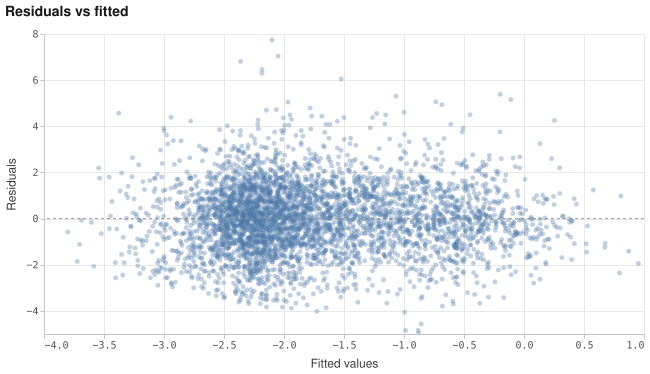

In [3]:
mb.plot.plot_residuals(mean_only)

In [4]:
specification = {"mu": f"stunting ~ {terms}", "sigma": f"stunting ~ {terms}"}
lss = mb.gamboostLSS(specification, data=data, families=mb.GaussianLSS(),
                     control=mb.boost_control(300, 0.1))

sigma = np.asarray(lss.fitted(parameter="sigma", type="response"))
print(f"fitted sigma ranges {sigma.min():.2f} to {sigma.max():.2f} "
      f"— a factor of {sigma.max() / sigma.min():.1f}")

fitted sigma ranges 0.95 to 2.55 — a factor of 2.7


## Location-scale model: `GaussianLSS`

The fitted conditional standard deviation ranges from 0.95 to 2.55, a factor of
2.7 across these children. The variance is not constant.

The update counts below (the number of boosting steps in which each predictor's term was fitted) show which predictors account for that variation, and
the smooth effects show each predictor's contribution to the linear predictor for log-sigma (the log of the standard deviation, which the model fits additively).

In [5]:
from collections import Counter

# Count the public selection paths separately for mean and scale.
for parameter, selected in lss.selected.items():
    ordered = dict(Counter(selected).most_common())
    print(f"{parameter:6s} updates by predictor: {ordered}")


mu     updates by predictor: {'cage': 127, 'cbmi': 78, 'mbmi': 50, 'mage': 45}
sigma  updates by predictor: {'mage': 172, 'cage': 48, 'cbmi': 45, 'mbmi': 35}


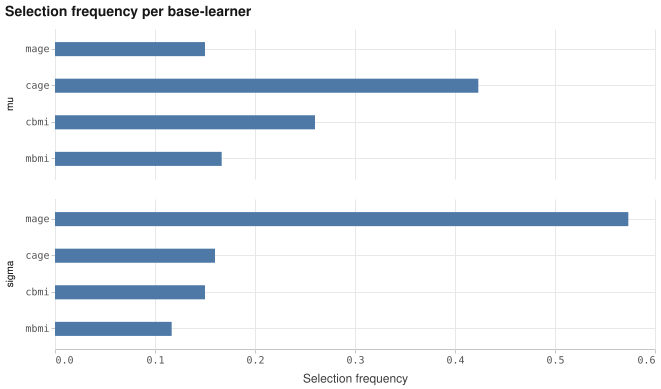

In [6]:
mb.plot.plot_lss_selected(lss)

log-sigma effect swing per predictor:
  cbmi  0.580
  mbmi  0.249
  cage  0.284
  mage  0.399


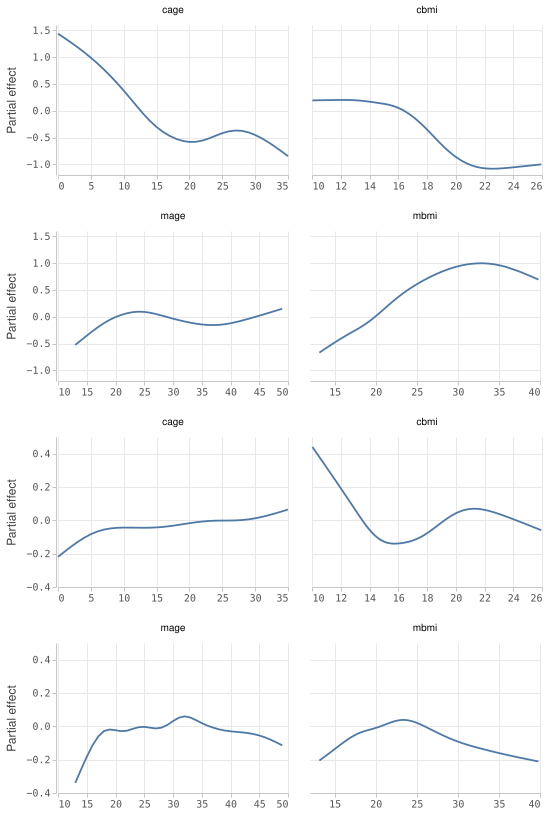

In [7]:
import altair as alt
# Plot the quantities interpreted in the following paragraph.
effects_mu = lss.partial_effects(parameter="mu")
effects_sigma = lss.partial_effects(parameter="sigma")

print("log-sigma effect swing per predictor:")
for name, (x, y) in effects_sigma.items():
    print(f"  {name:5s} {y.max() - y.min():.3f}")


def effects_chart(effects, title):
    rows = []
    for name, (x, y) in effects.items():
        order = np.argsort(x)
        rows.extend({"predictor": name, "x": float(x[i]),
                     "effect": float(y[i])} for i in order)
    frame = pl.DataFrame(rows)
    return (alt.Chart(frame).mark_line(strokeWidth=1.8, color="#4e79a7").encode(
        x=alt.X("x:Q", title=None),
        y=alt.Y("effect:Q", title="Partial effect"),
    ).properties(title=title, width=230, height=150).facet(
        facet=alt.Facet("predictor:N", title=None), columns=2
    ).resolve_scale(x="independent"))


alt.vconcat(effects_chart(effects_mu, "mu"),
            effects_chart(effects_sigma, "sigma"))


The mean (mu) model is dominated by the child's age, which takes 127 of its 300
updates, and the sigma model by the mother's age, at 172 of 300, with the
remainder spread across the other three predictors. None of the four sigma
effects is flat, and each shifts the log-sigma predictor by several tenths in
either direction. The largest is the child's BMI effect at 0.580 in log units,
followed by the mother's age at 0.399.

The residual check against child age showed only a rise from 1.43 to 1.55. The variation is spread across the predictors, which a check against one variable cannot combine.

## Held-out prediction intervals

A varying sigma matters to the extent that it changes a quantity the programme
would use. Here it changes the prediction interval. The sample is split, both
models are fitted on the same training set, and their 90% prediction intervals
are compared on held-out data.


In [8]:
rng = np.random.default_rng(0)
order = rng.permutation(n)
train_rows, test_rows = order[:3000], order[3000:]
train = {k: np.asarray(v)[train_rows] for k, v in data.items()}
test = {k: np.asarray(v)[test_rows] for k, v in data.items()}
observed = np.asarray(test["stunting"])
# Fix the random draw so the resampling result is reproducible.
constant = mb.gamboost(f"stunting ~ {terms}", data=train, family=mb.Gaussian(),
                       control=mb.boost_control(300, 0.1))
centre = np.asarray(constant.predict(newdata=test))
spread = float(np.std(np.asarray(train["stunting"])
                      - np.asarray(constant.fitted_), ddof=1))
lower_c, upper_c = centre - 1.645 * spread, centre + 1.645 * spread

varying = mb.gamboostLSS(specification, data=train, families=mb.GaussianLSS(),
                         control=mb.boost_control(300, 0.1))
interval = varying.prediction_interval(newdata=test, level=0.90)
lower_v = np.asarray(interval["lower"])
upper_v = np.asarray(interval["upper"])

for label, lo, hi in (("constant sigma", lower_c, upper_c),
                      ("varying sigma", lower_v, upper_v)):
    covered = np.mean((observed >= lo) & (observed <= hi)) * 100
    widths = hi - lo
    print(f"{label:15s} coverage {covered:5.1f}%   "
          f"width {widths.mean():.2f} "
          f"(range {widths.min():.2f} to {widths.max():.2f})")


constant sigma  coverage  89.2%   width 4.85 (range 4.85 to 4.85)
varying sigma   coverage  88.6%   width 4.79 (range 3.33 to 7.94)


## Coverage by fitted sigma

Both intervals cover about 89% of the held-out data against a nominal 90%. On
that number the constant-sigma interval is adequate. The held-out split treats children as independent, so the clustering by village is not reflected in these coverage figures.

The aggregate does not show how the coverage is distributed. Splitting the test
set by the fitted sigma from the varying model orders the children by how
uncertain their outcome is, and coverage can then be measured within each
quarter.


In [9]:
fitted_sigma = np.asarray(varying.params(newdata=test, type="response")["sigma"])
cuts = np.quantile(fitted_sigma, [0, 0.25, 0.5, 0.75, 1.0])

rows = []
for i in range(4):
    band = (fitted_sigma >= cuts[i]) & (fitted_sigma <= cuts[i + 1])
    rows.append({
        "fitted sigma": f"{cuts[i]:.2f}-{cuts[i + 1]:.2f}",
        "n": int(band.sum()),
        "constant": round(float(np.mean((observed[band] >= lower_c[band])
                                        & (observed[band] <= upper_c[band])) * 100), 1),
        "varying": round(float(np.mean((observed[band] >= lower_v[band])
                                       & (observed[band] <= upper_v[band])) * 100), 1),
    })
display(pl.DataFrame(rows))

fitted sigma,n,constant,varying
"""1.01-1.35""",250,91.6,84.8
"""1.35-1.42""",250,92.4,91.2
"""1.42-1.53""",250,91.2,90.0
"""1.53-2.41""",250,81.6,88.4


The constant-sigma interval covers 91% of the quarter with the most predictable
outcomes and 82% of the quarter with the least predictable. The two errors fall
in opposite quarters and cancel in the average, which is why the aggregate
reads 89%. The children with the most uncertain outcomes receive an interval
labelled 90% that covers 82%, at the same width as everyone else's.

The varying-sigma interval is flatter across quarters: 85%, 91%, 90% and 88%, read from the most predictable quarter to the least predictable.
It narrows where the outcome is predictable and widens where it is not, with
widths from 3.33 to 7.94 against a constant 4.85, and under-covers the bottom
quarter where its widths are tightest.

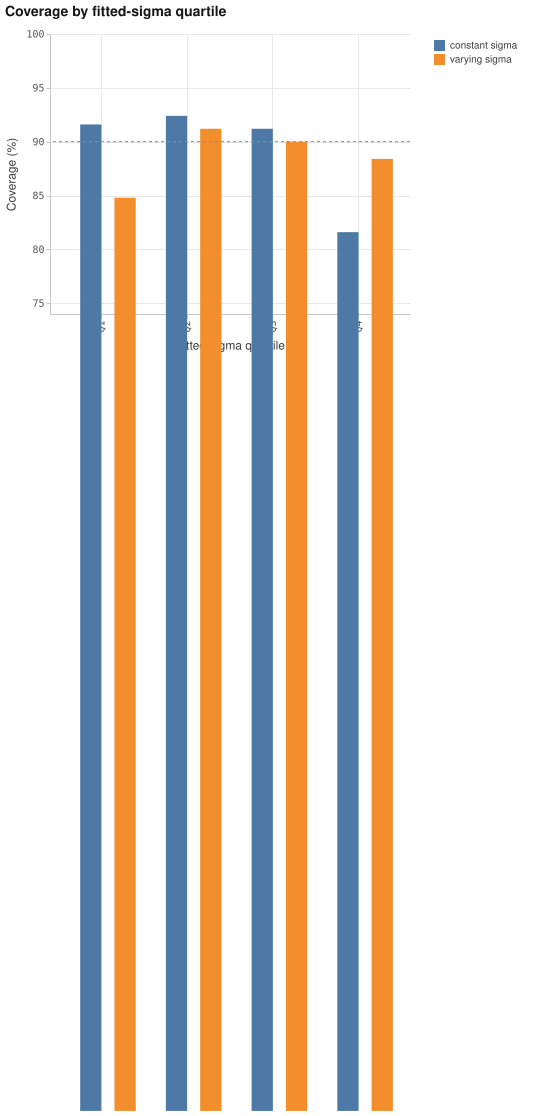

In [10]:
import altair as alt
# Plot the quantities interpreted in the following paragraph.
cuts = np.quantile(fitted_sigma, [0, 0.25, 0.5, 0.75, 1.0])
rows = []
for i in range(4):
    band = (fitted_sigma >= cuts[i]) & (fitted_sigma <= cuts[i + 1])
    rows.append({"quartile": f"Q{i + 1}", "interval": "constant sigma",
                 "coverage": float(np.mean((observed[band] >= lower_c[band])
                                           & (observed[band] <= upper_c[band])) * 100)})
    rows.append({"quartile": f"Q{i + 1}", "interval": "varying sigma",
                 "coverage": float(np.mean((observed[band] >= lower_v[band])
                                           & (observed[band] <= upper_v[band])) * 100)})
frame = pl.DataFrame(rows)

bars = alt.Chart(frame).mark_bar().encode(
    x=alt.X("quartile:N", title="Fitted-sigma quartile"),
    xOffset=alt.XOffset("interval:N"),
    y=alt.Y("coverage:Q", title="Coverage (%)", scale=alt.Scale(domain=[75, 100])),
    color=alt.Color("interval:N", title=None),
    tooltip=[alt.Tooltip("interval:N", title="Interval"),
             alt.Tooltip("coverage:Q", format=".1f", title="Coverage (%)")],
).properties(width=360, height=280)

ref = alt.Chart(pl.DataFrame({"coverage": [90]})).mark_rule(
    color="#8d8d8d", strokeDash=[3, 3]).encode(y="coverage:Q")

(bars + ref).properties(title="Coverage by fitted-sigma quartile")


## Conclusions

The fitted conditional standard deviation varies by a factor of about 2.7
across these children, with contributions from all four predictors,
and intervals built on a constant variance are miscalibrated where the variance
is highest: the constant-sigma 90% interval covers 82% of the quarter with the
largest fitted sigma.

The varying-sigma model is closer to nominal coverage at the top of its fitted
sigma range and under-covers at the bottom. Reporting coverage by sigma group
reveals this remaining miscalibration.

Every quantity here is an association, including the fitted sigma. The survey
is observational, and mother's age stands in for parity, economic circumstance
and access to care, none of which are measured.

Two checks produced the result: measuring coverage conditionally by stratifying
on a fitted quantity, and fitting the variance rather than inspecting residuals
against a single predictor chosen in advance. When decisions concern children
with the least predictable outcomes, coverage should be reported for that group;
overall coverage does not describe it. A distributional model estimates
quantities a mean model does not express: where the spread is, and how wide an
interval should be.